In [30]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

In [3]:
data = r"data\household_energy_consumption_1800.csv"
df = pd.read_csv(data)

In [4]:
df.head()

,household_size,floor_area_m2,average_daily_temperature_c,air_conditioner_units,average_ac_hours_per_day,refrigerator_count,freezer_count,television_count,fan_count,washing_machine_present,electric_water_heater_present,daily_occupancy_hours,weekend_usage_factor,cooking_sessions_per_day,monthly_energy_consumption_kwh
0,1,30.5,27.9,0,0.0,1,0,0,1,1,0,10.5,1.26,1.2,137.6
1,7,118.2,25.0,1,3.8,1,0,6,7,1,1,16.7,1.37,6.8,493.6
2,6,111.0,31.1,1,8.6,1,2,6,1,1,0,21.1,1.16,6.8,384.9
3,4,61.9,34.5,1,6.4,1,1,2,5,0,0,20.3,1.14,4.0,257.2
4,4,93.0,25.9,5,6.2,1,0,1,4,1,1,20.1,1.48,4.0,325.3


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   household_size                  1800 non-null   int64  
 1   floor_area_m2                   1800 non-null   float64
 2   average_daily_temperature_c     1800 non-null   float64
 3   air_conditioner_units           1800 non-null   int64  
 4   average_ac_hours_per_day        1800 non-null   float64
 5   refrigerator_count              1800 non-null   int64  
 6   freezer_count                   1800 non-null   int64  
 7   television_count                1800 non-null   int64  
 8   fan_count                       1800 non-null   int64  
 9   washing_machine_present         1800 non-null   int64  
 10  electric_water_heater_present   1800 non-null   int64  
 11  daily_occupancy_hours           1800 non-null   float64
 12  weekend_usage_factor            18

In [6]:
df.shape

(1800, 15)

In [7]:
df.ndim

2

In [8]:
df.tail()

,household_size,floor_area_m2,average_daily_temperature_c,air_conditioner_units,average_ac_hours_per_day,refrigerator_count,freezer_count,television_count,fan_count,washing_machine_present,electric_water_heater_present,daily_occupancy_hours,weekend_usage_factor,cooking_sessions_per_day,monthly_energy_consumption_kwh
1795,2,28.3,25.2,0,0.0,1,1,1,1,1,1,13.7,1.25,2.3,181.7
1796,8,124.4,32.4,2,1.5,1,1,3,5,1,0,16.4,0.93,6.3,309.0
1797,2,56.1,30.4,5,7.5,1,1,0,0,1,0,15.9,1.25,1.5,332.5
1798,4,72.8,27.9,3,2.3,1,0,3,4,1,1,16.7,1.21,5.8,310.8
1799,5,88.1,26.6,3,0.5,2,2,2,1,1,1,10.0,1.14,6.0,417.1


In [9]:
df.sample(10)

,household_size,floor_area_m2,average_daily_temperature_c,air_conditioner_units,average_ac_hours_per_day,refrigerator_count,freezer_count,television_count,fan_count,washing_machine_present,electric_water_heater_present,daily_occupancy_hours,weekend_usage_factor,cooking_sessions_per_day,monthly_energy_consumption_kwh
1661,5,83.2,20.0,2,1.9,1,1,0,4,1,0,19.6,1.09,5.0,258.9
98,6,101.4,19.8,0,0.0,1,2,4,4,1,1,13.5,0.91,4.9,419.6
1713,6,123.4,29.4,3,10.3,2,2,4,4,0,0,17.9,1.09,5.8,504.4
664,5,110.7,19.5,2,5.8,1,0,2,4,1,1,12.6,1.24,2.9,300.8
1752,6,93.7,33.2,0,0.0,2,1,3,3,1,1,17.6,1.24,6.9,330.5
1701,2,62.4,31.3,1,2.5,1,0,1,0,0,0,10.7,0.81,4.0,135.6
1753,4,67.7,31.4,1,2.5,1,2,6,5,0,0,15.8,1.12,4.0,329.8
260,7,114.6,21.9,3,7.0,2,1,6,3,0,0,16.5,1.06,8.0,375.3
1383,8,130.5,27.6,1,1.8,2,1,4,3,1,1,16.7,0.97,7.4,473.1
1618,1,42.9,24.8,2,0.8,1,0,0,0,0,0,12.7,1.22,4.0,102.5


In [10]:
df.isna().any()

household_size                    False
floor_area_m2                     False
average_daily_temperature_c       False
air_conditioner_units             False
average_ac_hours_per_day          False
refrigerator_count                False
freezer_count                     False
television_count                  False
fan_count                         False
washing_machine_present           False
electric_water_heater_present     False
daily_occupancy_hours             False
weekend_usage_factor              False
cooking_sessions_per_day          False
monthly_energy_consumption_kwh    False
dtype: bool

In [11]:
df.duplicated().sum()

np.int64(0)

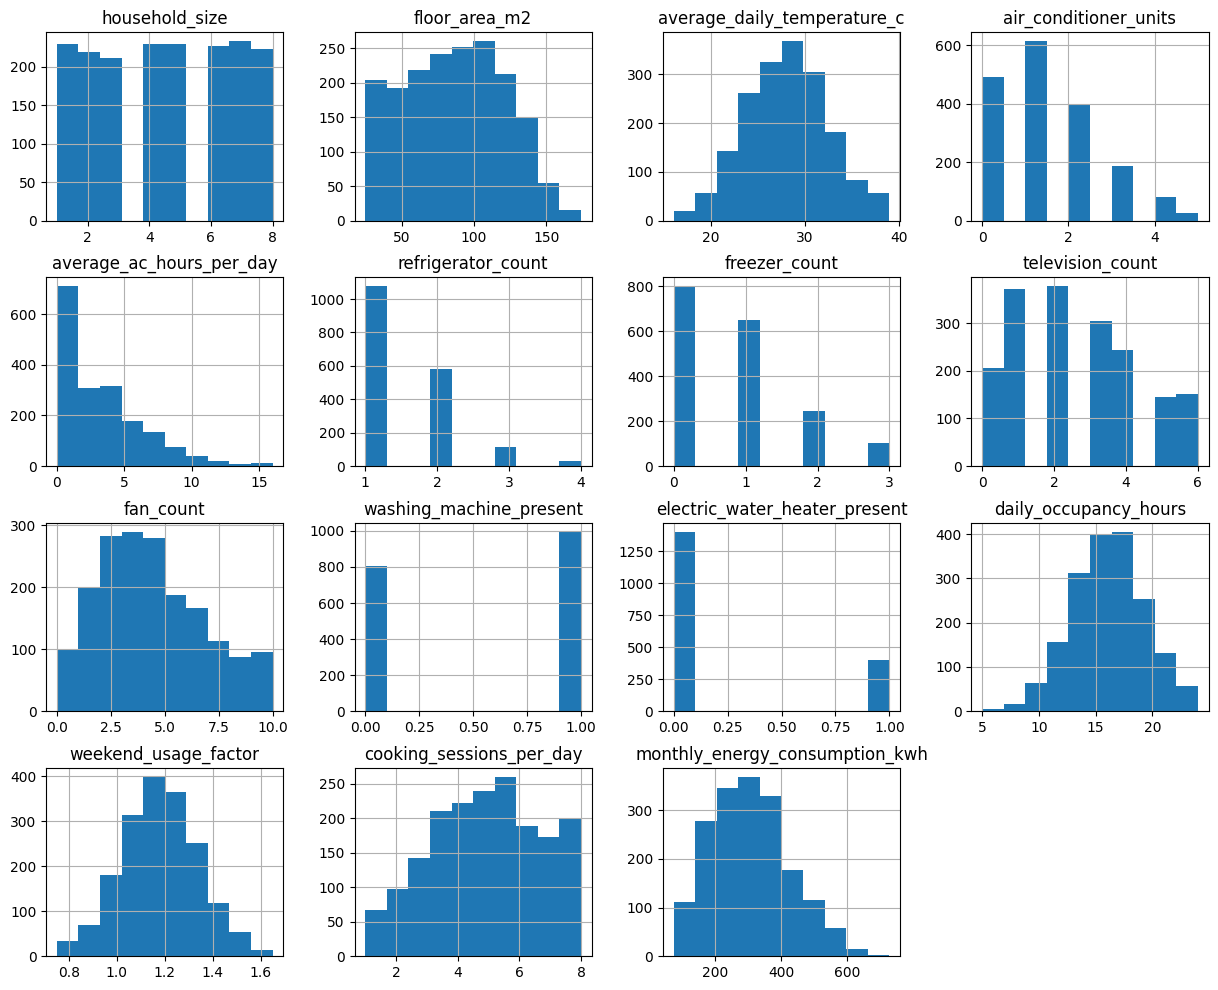

In [12]:
df.hist(figsize = (15,12))
plt.show()

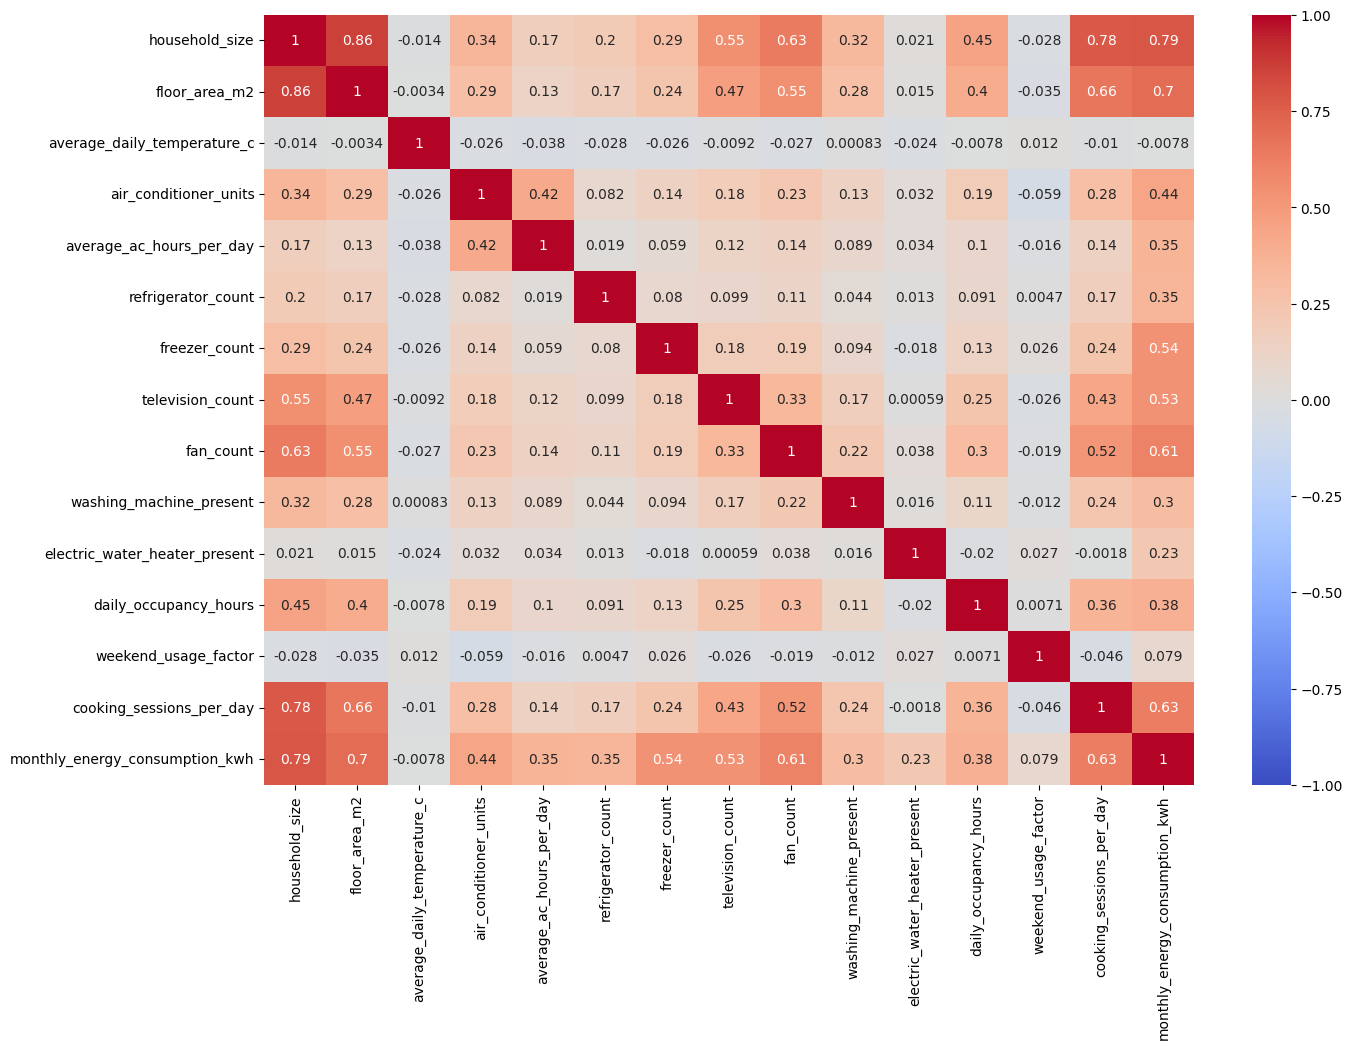

In [13]:
corr = df.corr(numeric_only = True)
plt.figure(figsize = (15, 10))
sns.heatmap(corr, annot = True, vmin = -1, vmax = 1, cmap = 'coolwarm')

plt.show()

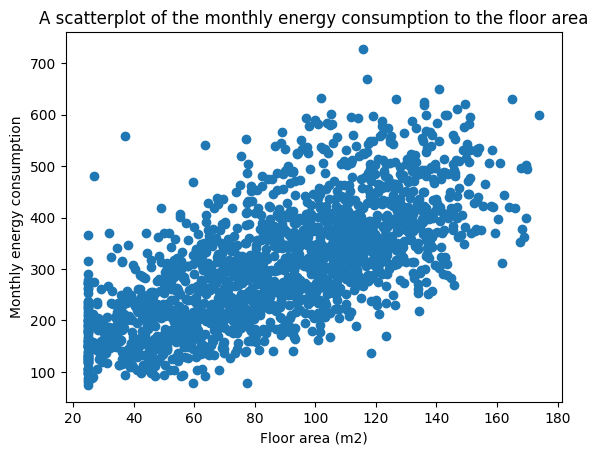

In [14]:
plt.scatter(df['floor_area_m2'],df['monthly_energy_consumption_kwh'])
plt.title("A scatterplot of the monthly energy consumption to the floor area")
plt.xlabel("Floor area (m2)")
plt.ylabel("Monthly energy consumption")
plt.show()

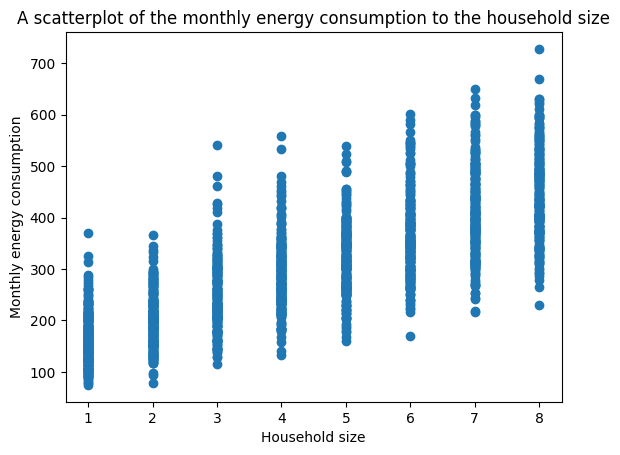

In [15]:
plt.scatter(df['household_size'],df['monthly_energy_consumption_kwh'])
plt.title("A scatterplot of the monthly energy consumption to the household size")
plt.xlabel("Household size")
plt.ylabel("Monthly energy consumption")
plt.show()

### Proceeding with the model 

We'll be working with the neural network model

#### Feature selection

In [16]:
columns_present = df.columns.to_list()
# print(columns_present)
columns_present.pop(-1)
# print(columns_present)

x = df[columns_present].to_numpy()
y = np.array(df["monthly_energy_consumption_kwh"])

#### Splitting train and test data

In [17]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state = 42, test_size = 0.2)

In [18]:
x_train.shape

(1440, 14)

#### Feature scaling and standardisation

In [19]:
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
# print(x_test_scaled)
# print(x_train_scaled)

#### Building the model

In [20]:
model = Sequential([Input(shape = (x_train_scaled.shape[1],)), Dense(units = 8, activation = 'relu'), Dense(units = 3, activation = 'relu'), Dense(units = 1, activation = "linear")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │             120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              27 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               4 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error', metrics = ['mae'])
history = model.fit(x_train_scaled, y_train, epochs = 500)

Epoch 1/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 106703.2812 - mae: 305.8139
Epoch 2/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 106280.0469 - mae: 305.1385
Epoch 3/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 105631.8438 - mae: 304.1300
Epoch 4/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 104542.3906 - mae: 302.4483
Epoch 5/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 103120.0547 - mae: 300.2589
Epoch 6/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 101364.4297 - mae: 297.5400
Epoch 7/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 99239.9219 - mae: 294.2178 
Epoch 8/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 96706.8359 - mae: 290.2075
Epoch 9/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 93508.4922 - mae: 285.0980
Epoch 10/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 89527.7812 - mae: 278.6229
Epoch 11/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 84945.8047 - mae: 270.9125
Epoch 12/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4m

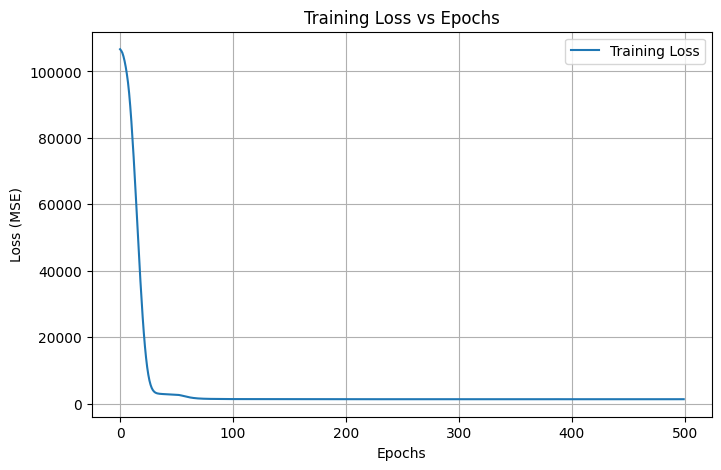

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Training Loss vs Epochs')

plt.legend()
plt.grid()
plt.show()

In [23]:
model2 = LinearRegression()
model2.fit(x_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[92.2 ,56.54,16.24,...,22.22,61.66,11.45]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.18
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,14
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](14,)","[22.34,16.25,15.46,..., 5.8 , 5.41, 3.42]"


In [28]:
y_pred = model2.predict(x_test_scaled).reshape(-1, 1)
y_test = y_test.reshape(-1, 1)
print(f"MAE for the linear regression model: {mean_absolute_error(y_test , y_pred)}")


MAE for the linear regression model: 30.461755647597414


In [25]:
# Linear Regression
lr_predictions = model2.predict(x_test_scaled)
# Neural Network
nn_predictions = model.predict(x_test_scaled).flatten()

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


### Comparing our neural network with the linear regression model

In [34]:
rmse = np.sqrt(mean_squared_error(y_test , nn_predictions))
rmse_linear = np.sqrt(mean_squared_error(y_test , lr_predictions))
print("Neural Network")
print(f"MAE: {mean_absolute_error(y_test , nn_predictions)}")
print(f"RMSE: {rmse}")
print(f"R_squared: {r2_score(y_test , nn_predictions)}")
print("\n")
print("Linear Regression model")
print(f"MAE: {mean_absolute_error(y_test , lr_predictions)}")
print(f"RMSE: {rmse_linear}")
print(f"R_squared: {r2_score(y_test , lr_predictions)}")

Neural Network
MAE: 30.680981805589465
RMSE: 38.909669176622735
R_squared: 0.9034486811082238


Linear Regression model
MAE: 30.461755647597414
RMSE: 38.81428123060669
R_squared: 0.9039214963817402


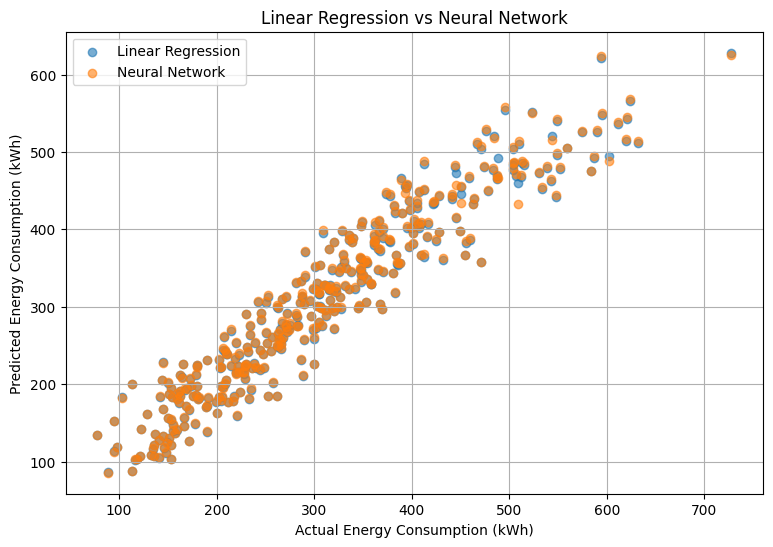

In [26]:

plt.figure(figsize=(9, 6))

plt.scatter(y_test, lr_predictions, label='Linear Regression', alpha=0.6)

plt.scatter(y_test, nn_predictions, label='Neural Network', alpha=0.6)

plt.xlabel('Actual Energy Consumption (kWh)')
plt.ylabel('Predicted Energy Consumption (kWh)')
plt.title('Linear Regression vs Neural Network')

plt.legend()
plt.grid()
plt.show()

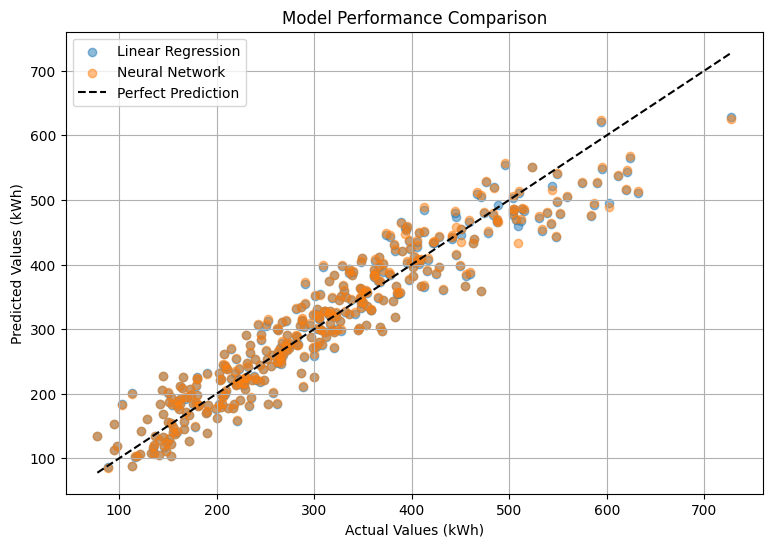

In [27]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, lr_predictions, label='Linear Regression', alpha=0.5)
plt.scatter(y_test, nn_predictions, label='Neural Network', alpha=0.5)

minimum = min(y_test.min(), lr_predictions.min(), nn_predictions.min())
maximum = max(y_test.max(), lr_predictions.max(), nn_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], 'k--', label='Perfect Prediction')

plt.xlabel('Actual Values (kWh)')
plt.ylabel('Predicted Values (kWh)')
plt.title('Model Performance Comparison')

plt.legend()
plt.grid()
plt.show()